# Setup and Data Loading


In [1]:
import os, time, json, pickle, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF   # <-- NEW: CRF layer for Experiment 2

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| PyTorch:", torch.__version__)


Device: cpu | PyTorch: 2.15.0+cpu


In [2]:
PKL_PATH = "processed.pkl"

with open(PKL_PATH, "rb") as f:
    P = pickle.load(f)

print("Keys in processed.pkl:", list(P.keys()))

word2id = P["word2id"]
tag2id, id2tag = P["tag2id"], P["id2tag"]
intent2id, id2intent = P["intent2id"], P["id2intent"]
embedding_matrix = P["embedding_matrix"]
N_TAGS, N_INTENTS = len(tag2id), len(intent2id)

def to_tensors(arrays):
    X, Y_tags, Y_intent, lengths = arrays
    return [torch.from_numpy(a) for a in (X, Y_tags, Y_intent, lengths)]

train_t = to_tensors(P["train_arrays"])
dev_t   = to_tensors(P["dev_arrays"])
test_t  = to_tensors(P["test_arrays"])

assert len(train_t[0]) == 11514, len(train_t[0])
assert len(dev_t[0])   == 2033,  len(dev_t[0])
assert len(test_t[0])  == 2974,  len(test_t[0])
print(f"Train examples: {len(train_t[0])} | Dev examples: {len(dev_t[0])} | Test examples: {len(test_t[0])}")
print(f"Vocab: {len(word2id)} | BIO tags: {N_TAGS} | Intents: {N_INTENTS} | Embedding matrix: {embedding_matrix.shape}")

Keys in processed.pkl: ['train_data', 'dev_data', 'test_data', 'train_arrays', 'dev_arrays', 'test_arrays', 'word2id', 'tag2id', 'id2tag', 'intent2id', 'id2intent', 'embedding_matrix']
Train examples: 11514 | Dev examples: 2033 | Test examples: 2974
Vocab: 5304 | BIO tags: 111 | Intents: 60 | Embedding matrix: (5304, 300)


In [3]:
def batches(tensors, batch_size, shuffle=False, generator=None):
    """Yield (x, tag_labels, intent_labels, lengths); padding is trimmed to the longest sequence in the batch."""
    X, Y_tags, Y_intent, lengths = tensors
    idx = torch.randperm(len(X), generator=generator) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), batch_size):
        b = idx[i:i + batch_size]
        L = int(lengths[b].max())
        yield (X[b, :L].to(device), Y_tags[b, :L].to(device),
               Y_intent[b].to(device), lengths[b])

x, yt, yi, ln = next(batches(train_t, 4))
print("Sample batch shapes -> x:", tuple(x.shape), "| tags:", tuple(yt.shape), "| intent:", tuple(yi.shape), "| lengths:", ln.tolist())

Sample batch shapes -> x: (4, 8) | tags: (4, 8) | intent: (4,) | lengths: [8, 8, 2, 1]


## Stage-2 model definition (AI-enhanced)

Starts from the Stage-1 joint BiLSTM and adds a **CRF layer** on the slot outputs. Changes are based on AI-assisted error analysis of the Stage-1 dev predictions.

- **Input**: token-id sequence of `utt` (whitespace tokens, train-only vocabulary, `<UNK>`=1, `<PAD>`=0). Nothing else is used as input.
- **Embedding**: 300-d GloVe (6B), fine-tuned; embedding dropout 0.5.
- **Encoder**: 2-layer BiLSTM, 256 hidden units per direction, inter-layer dropout 0.5, packed sequences.
- **Slot head**: Dropout → Linear(512 → 111) emission scores → **CRF** (111×111 learned tag-transition scores). Decoding uses Viterbi (`crf.decode`) to pick the best whole tag sequence instead of per-word argmax.
- **Intent head**: masked max-pool ‖ mean-pool (1024-d) → Linear(1024 → 60).
- **Loss**: L = CE(intent) + CRF negative log-likelihood of the gold tag sequence (averaged per token); padding masked out.
- **Optimizer**: Adam, lr 1e-3, gradient clipping 5.0, batch size 32, seed 42.
- **Model selection**: highest dev (intent acc + slot micro-F1) / 2; early-stopping patience 8, max 40 epochs.
- **Why the CRF**: the Stage-1 diagnosis found 187 wrong slot boundaries, 221 spurious slots and 69 invalid BIO transitions (I- without a matching B-). The CRF scores whole tag sequences, so it learns valid transitions and cleaner boundaries.
- **Tried and not kept (Exp 1)**: word dropout 0.1 reduced overfitting and raised intent accuracy, but lowered slot F1 (dev score 82.80 vs 82.91 baseline).
- **Parameters**: 4,441,930 total / trainable (Stage-1 4,429,387 + 12,543 CRF), under the 20M cap.


In [4]:
class JointModel(nn.Module):
    def __init__(self, emb_matrix, n_tags, n_intents, hidden=256, layers=2, dropout=0.4):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.emb_drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, num_layers=layers, batch_first=True,
                            bidirectional=True, dropout=dropout if layers > 1 else 0)
        self.drop = nn.Dropout(dropout)
        self.slot_head = nn.Linear(2 * hidden, n_tags)
        self.intent_head = nn.Linear(4 * hidden, n_intents)
        self.crf = CRF(n_tags, batch_first=True)   # <-- NEW: learns which tag can follow which (e.g. O -> I-time is invalid)

    def forward(self, x, lengths):
        e = self.emb_drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        out = self.drop(out)
        slot_logits = self.slot_head(out)
        mask = (x != 0).unsqueeze(-1)
        mx = out.masked_fill(~mask, -1e9).max(dim=1).values
        mean = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        intent_logits = self.intent_head(torch.cat([mx, mean], dim=-1))
        return intent_logits, slot_logits


In [5]:
# ---- Parameter budget check (cap: 20M for the whole system, word vectors included) ----
PARAM_CAP = 20_000_000
def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable

_m = JointModel(embedding_matrix, N_TAGS, N_INTENTS)
TOTAL_PARAMS, TRAINABLE_PARAMS = count_params(_m)
print(f"Embedding params     : {_m.emb.weight.numel():,}")
print(f"LSTM params          : {sum(p.numel() for p in _m.lstm.parameters()):,}")
print(f"Slot head params     : {sum(p.numel() for p in _m.slot_head.parameters()):,}")
print(f"Intent head params   : {sum(p.numel() for p in _m.intent_head.parameters()):,}")
print(f"Total parameters     : {TOTAL_PARAMS:,}")
print(f"Trainable parameters : {TRAINABLE_PARAMS:,}")
assert TOTAL_PARAMS <= PARAM_CAP, "Exceeds the 20M parameter cap!"
print(f"OK: {TOTAL_PARAMS:,} <= {PARAM_CAP:,} ({100 * TOTAL_PARAMS / PARAM_CAP:.2f}% of the cap)")
del _m

Embedding params     : 1,591,200
LSTM params          : 2,719,744
Slot head params     : 56,943
Intent head params   : 61,500
Total parameters     : 4,441,930
Trainable parameters : 4,441,930
OK: 4,441,930 <= 20,000,000 (22.21% of the cap)


# Evaluation helper used during training


In [6]:
def tags_to_spans(tags):
    """BIO tag strings -> set of (slot_type, start, end_exclusive)."""
    spans, cur_type, start = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        if t.startswith("I-") and t[2:] == cur_type:
            continue
        if cur_type is not None:
            spans.append((cur_type, start, i))
        cur_type, start = (t[2:], i) if t != "O" else (None, None)
    return set(spans)

assert tags_to_spans(["O", "B-time", "I-time", "O", "B-date"]) == {("time", 1, 3), ("date", 4, 5)}

def compute_loss(model, intent_logits, slot_logits, y_intent, y_tags, slot_weight=1.0):   # <-- CHANGED: takes model
    loss_i = F.cross_entropy(intent_logits, y_intent)
    mask = y_tags != -100                                                                   # <-- CHANGED: real words only
    loss_s = -model.crf(slot_logits, y_tags.masked_fill(~mask, 0), mask=mask, reduction="token_mean")  # <-- CHANGED: CRF loss
    return loss_i + slot_weight * loss_s, loss_i, loss_s

@torch.no_grad()
def evaluate(model, tensors, batch_size=256, slot_weight=1.0):
    """Returns loss (mean per batch), intent accuracy (%), slot micro-F1 (%), exact-match (%)."""
    model.eval()
    n = n_correct = n_exact = tp = fp = fn = 0
    loss_sum, n_batches = 0.0, 0
    for x, y_tags, y_intent, lengths in batches(tensors, batch_size):
        intent_logits, slot_logits = model(x, lengths)
        loss, _, _ = compute_loss(model, intent_logits, slot_logits, y_intent, y_tags, slot_weight)   # <-- CHANGED
        loss_sum += loss.item(); n_batches += 1
        pred_intent = intent_logits.argmax(-1).cpu()
        pred_paths = model.crf.decode(slot_logits, mask=(x != 0))                                     # <-- CHANGED: CRF decoding
        gold_intent, gold_tags = y_intent.cpu(), y_tags.cpu()
        for i in range(len(x)):
            L = int(lengths[i])
            pred = tags_to_spans([id2tag[int(t)] for t in pred_paths[i]])                             # <-- CHANGED
            gold = tags_to_spans([id2tag[int(t)] for t in gold_tags[i, :L]])
            tp += len(pred & gold); fp += len(pred - gold); fn += len(gold - pred)
            ok = int(pred_intent[i]) == int(gold_intent[i])
            n_correct += ok; n_exact += (ok and pred == gold); n += 1
    f1 = 100 * 2 * tp / max(2 * tp + fp + fn, 1)
    return {"loss": loss_sum / n_batches, "intent_acc": 100 * n_correct / n,
            "slot_f1": f1, "exact_match": 100 * n_exact / n}


# Training


In [7]:
CONFIG = dict(epochs=40, batch_size=32, lr=1e-3, slot_weight=1.0, hidden=256, layers=2,
              dropout=0.5, patience=8, clip=5.0, seed=SEED, word_dropout=0.0, crf=True)   # <-- CHANGED (Exp 2): word dropout off, CRF on
CKPT_PATH = "stage2_best.pt"              # new name, keeps Stage-1 file safe
LOG_PATH  = "stage2_training_log.json"

def combined_score(m):
    return (m["intent_acc"] + m["slot_f1"]) / 2

def train_baseline(cfg=CONFIG, ckpt_path=CKPT_PATH):
    torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"]); random.seed(cfg["seed"])
    g = torch.Generator().manual_seed(cfg["seed"])
    model = JointModel(embedding_matrix, N_TAGS, N_INTENTS, cfg["hidden"], cfg["layers"], cfg["dropout"]).to(device)
    total, trainable = count_params(model)
    assert total <= PARAM_CAP
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])

    history, best_score, best_epoch, bad = [], -1.0, 0, 0
    t0 = time.time()
    for ep in range(1, cfg["epochs"] + 1):
        t_ep = time.time()
        model.train()
        s_tot = s_i = s_s = 0.0; nb = 0
        for x, y_tags, y_intent, lengths in batches(train_t, cfg["batch_size"], shuffle=True, generator=g):
            if cfg.get("word_dropout", 0) > 0:                                                    # word dropout (Exp 1); off when 0.0
                drop = (torch.rand(x.shape, device=x.device) < cfg["word_dropout"]) & (x != 0)
                x = x.masked_fill(drop, 1)                                                        # 1 = <UNK>
            intent_logits, slot_logits = model(x, lengths)
            loss, li, ls = compute_loss(model, intent_logits, slot_logits, y_intent, y_tags, cfg["slot_weight"])   # <-- CHANGED (Exp 2): pass model for CRF
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
            opt.step()
            s_tot += loss.item(); s_i += li.item(); s_s += ls.item(); nb += 1

        val = evaluate(model, dev_t, slot_weight=cfg["slot_weight"])
        score = combined_score(val)
        rec = dict(epoch=ep, train_loss=s_tot / nb, train_loss_intent=s_i / nb, train_loss_slot=s_s / nb,
                   val_loss=val["loss"], val_intent_acc=val["intent_acc"], val_slot_f1=val["slot_f1"],
                   val_exact_match=val["exact_match"], val_score=score, lr=opt.param_groups[0]["lr"],
                   epoch_time_s=time.time() - t_ep, elapsed_s=time.time() - t0)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad = score, ep, 0
            torch.save({"model_state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                        "epoch": ep, "val_score": score, "val_metrics": val, "config": cfg,
                        "total_params": total, "trainable_params": trainable}, ckpt_path)
        else:
            bad += 1
        rec["saved"] = improved
        history.append(rec)
        print(f"Epoch {ep:02d}/{cfg['epochs']} | train loss {rec['train_loss']:.4f} | val loss {rec['val_loss']:.4f} | "
              f"val intent acc {rec['val_intent_acc']:.2f}% | val slot F1 {rec['val_slot_f1']:.2f}% | "
              f"score {score:.2f} | {rec['epoch_time_s']:.1f}s (total {rec['elapsed_s']:.0f}s)"
              + ("  <- best, checkpoint saved" if improved else ""))
        if bad >= cfg["patience"]:
            print(f"Early stopping at epoch {ep} (no dev improvement for {cfg['patience']} epochs).")
            break

    with open(LOG_PATH, "w") as f:
        json.dump({"config": cfg, "total_params": total, "trainable_params": trainable,
                   "best_epoch": best_epoch, "best_val_score": best_score, "history": history}, f, indent=2)
    return history, best_epoch, best_score


In [8]:
history, best_epoch, best_score = train_baseline()

Epoch 01/40 | train loss 3.2862 | val loss 1.6641 | val intent acc 71.86% | val slot F1 42.64% | score 57.25 | 126.2s (total 126s)  <- best, checkpoint saved
Epoch 02/40 | train loss 1.3960 | val loss 1.0921 | val intent acc 81.51% | val slot F1 61.96% | score 71.73 | 126.5s (total 253s)  <- best, checkpoint saved
Epoch 03/40 | train loss 0.9953 | val loss 0.9412 | val intent acc 82.00% | val slot F1 70.08% | score 76.04 | 129.4s (total 382s)  <- best, checkpoint saved
Epoch 04/40 | train loss 0.7821 | val loss 0.8456 | val intent acc 84.26% | val slot F1 74.13% | score 79.19 | 132.3s (total 515s)  <- best, checkpoint saved
Epoch 05/40 | train loss 0.6328 | val loss 0.8429 | val intent acc 84.16% | val slot F1 75.34% | score 79.75 | 133.4s (total 648s)  <- best, checkpoint saved
Epoch 06/40 | train loss 0.5492 | val loss 0.7717 | val intent acc 85.78% | val slot F1 76.02% | score 80.90 | 134.2s (total 782s)  <- best, checkpoint saved
Epoch 07/40 | train loss 0.4643 | val loss 0.7769 | 

# Epoch-level training log

In [9]:
log_df = pd.DataFrame(history)
cols = ["epoch", "train_loss", "val_loss", "val_intent_acc", "val_slot_f1", "val_score", "epoch_time_s", "elapsed_s", "saved"]
with pd.option_context("display.max_rows", None, "display.width", 200):
    display(log_df[cols].round(4))

,epoch,train_loss,val_loss,val_intent_acc,val_slot_f1,val_score,epoch_time_s,elapsed_s,saved
0,1,3.2862,1.6641,71.8642,42.6396,57.2519,126.1955,126.1955,True
1,2,1.3960,1.0921,81.5052,61.9568,71.7310,126.4723,252.7248,True
2,3,0.9953,0.9412,81.9970,70.0783,76.0377,129.4270,382.2037,True
3,4,0.7821,0.8456,84.2597,74.1283,79.1940,132.3084,514.5623,True
4,5,0.6328,0.8429,84.1613,75.3414,79.7514,133.4192,648.0299,True
5,6,0.5492,0.7717,85.7846,76.0228,80.9037,134.2130,782.2929,True
6,7,0.4643,0.7769,85.5386,76.8659,81.2022,133.4589,915.8047,True
7,8,0.4026,0.7929,85.4894,77.3176,81.4035,134.3474,1050.1998,True
8,9,0.3572,0.7763,85.3910,78.2258,81.8084,134.0418,1184.2926,True
9,10,0.3167,0.8054,85.2927,79.2292,82.2610,132.3174,1316.6610,True


# Learning Curve


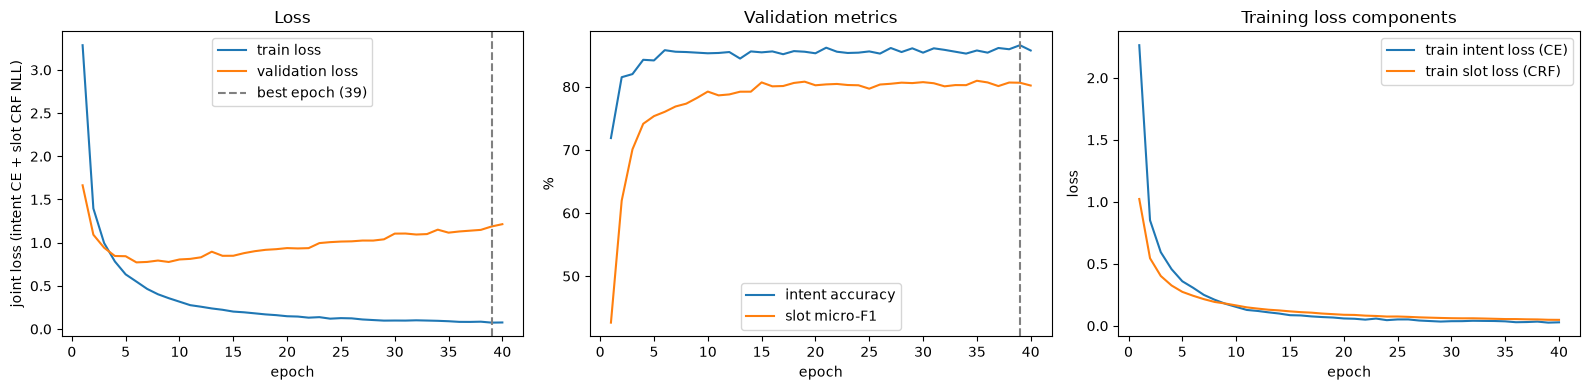

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ep = log_df["epoch"]

ax[0].plot(ep, log_df["train_loss"], label="train loss"); ax[0].plot(ep, log_df["val_loss"], label="validation loss")
ax[0].axvline(best_epoch, color="gray", ls="--", label=f"best epoch ({best_epoch})")
ax[0].set(title="Loss", xlabel="epoch", ylabel="joint loss (intent CE + slot CRF NLL)"); ax[0].legend()   # <-- CHANGED label

ax[1].plot(ep, log_df["val_intent_acc"], label="intent accuracy"); ax[1].plot(ep, log_df["val_slot_f1"], label="slot micro-F1")
ax[1].axvline(best_epoch, color="gray", ls="--")
ax[1].set(title="Validation metrics", xlabel="epoch", ylabel="%"); ax[1].legend()

ax[2].plot(ep, log_df["train_loss_intent"], label="train intent loss (CE)"); ax[2].plot(ep, log_df["train_loss_slot"], label="train slot loss (CRF)")   # <-- CHANGED labels
ax[2].set(title="Training loss components", xlabel="epoch", ylabel="loss"); ax[2].legend()                   # <-- CHANGED label

plt.tight_layout(); plt.savefig("stage2_learning_curves.png", dpi=150); plt.show()                         # <-- CHANGED: stage2 file name


# Selected Stage 2 Checkpoint

In [12]:
ckpt = torch.load(CKPT_PATH, map_location="cpu")
n_epochs_run = len(history)
print("=" * 60)
print("Selected Stage-2 checkpoint")
print(f"  Checkpoint file       : {CKPT_PATH}")
print(f"  Best epoch (index)    : {ckpt['epoch']}")
print(f"  Selection criterion   : (intent acc + slot micro-F1) / 2 on the validation split")
print(f"  Validation score      : {ckpt['val_score']:.2f}")
print(f"  Validation intent acc : {ckpt['val_metrics']['intent_acc']:.2f}%")
print(f"  Validation slot F1    : {ckpt['val_metrics']['slot_f1']:.2f}%")
print(f"  Epochs trained        : {n_epochs_run} (max {CONFIG['epochs']}, patience {CONFIG['patience']})")
print(f"  Total training time   : {history[-1]['elapsed_s']:.0f}s")
print(f"  Total / trainable params: {ckpt['total_params']:,} / {ckpt['trainable_params']:,}")
print("=" * 60)
assert ckpt["epoch"] == best_epoch and abs(ckpt["val_score"] - best_score) < 1e-9


Selected Stage-2 checkpoint
  Checkpoint file       : stage2_best.pt
  Best epoch (index)    : 39
  Selection criterion   : (intent acc + slot micro-F1) / 2 on the validation split
  Validation score      : 83.60
  Validation intent acc : 86.57%
  Validation slot F1    : 80.63%
  Epochs trained        : 40 (max 40, patience 8)
  Total training time   : 5318s
  Total / trainable params: 4,441,930 / 4,441,930
